In [1]:
print("Hello world")

Hello world


In [2]:
print("hello i am learning daya science")
print("this is my first project")

hello i am learning daya science
this is my first project


In [3]:
import pandas as pd


In [4]:
from sklearn.datasets import load_iris


iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
df ["flower"] = iris.target_names[iris.target]


In [5]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
df.shape

(150, 5)

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   flower             150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [8]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
flower               0
dtype: int64

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df.duplicated().sum()

np.int64(1)

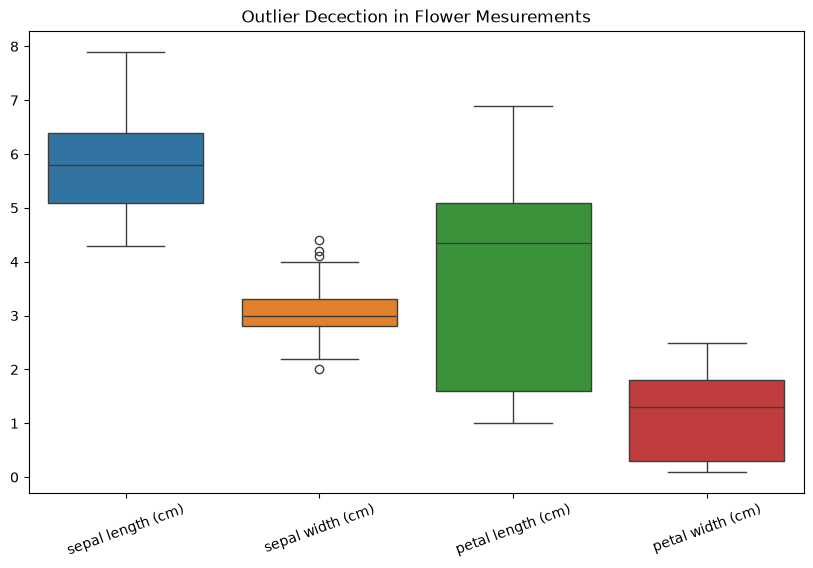

In [12]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df.drop(columns=["flower"]))
plt.title("Outlier Decection in Flower Mesurements")
plt.xticks(rotation=20)
plt.show()

In [13]:
columns = df.select_dtypes(include="number").columns

for col in columns:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1

    lower_limit = Q1- 1.5 * IQR
    upper_limit = Q3 +1.5 * IQR
    
    outliers = df[
    
    (df[col]< lower_limit) |
    (df[col]> upper_limit)
        ]
    print(col, ":", len(outliers),"possible outliers")

sepal length (cm) : 0 possible outliers
sepal width (cm) : 4 possible outliers
petal length (cm) : 0 possible outliers
petal width (cm) : 0 possible outliers


In [14]:
df.duplicated().sum()

np.int64(1)

In [15]:
duplicates = df[df.duplicated(keep=False)]
duplicates

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


In [16]:
df = df.drop_duplicates()
print("Dataset size after removing duplicates:", df.shape)

Dataset size after removing duplicates: (149, 5)


In [17]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
flower               0
dtype: int64

In [18]:
X = df.drop("flower",axis=1)
y =df["flower"]
print("Features:")
print(X.head())
print("Target")
print(y.head())

Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Target
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: flower, dtype: str


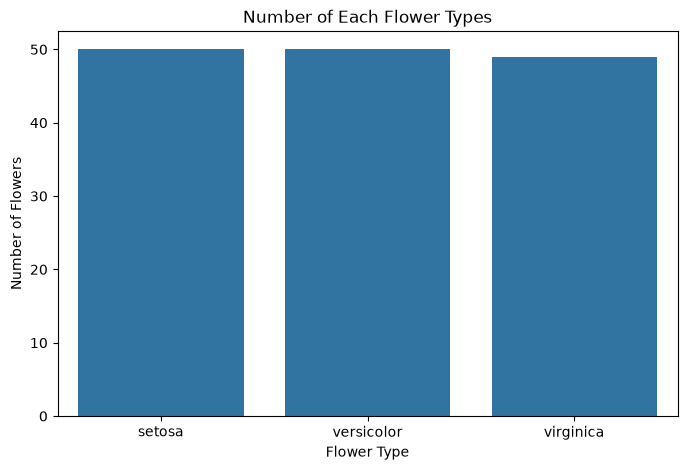

In [19]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="flower")
plt.title("Number of Each Flower Types")
plt.xlabel("Flower Type")
plt.ylabel("Number of Flowers")
plt.show()

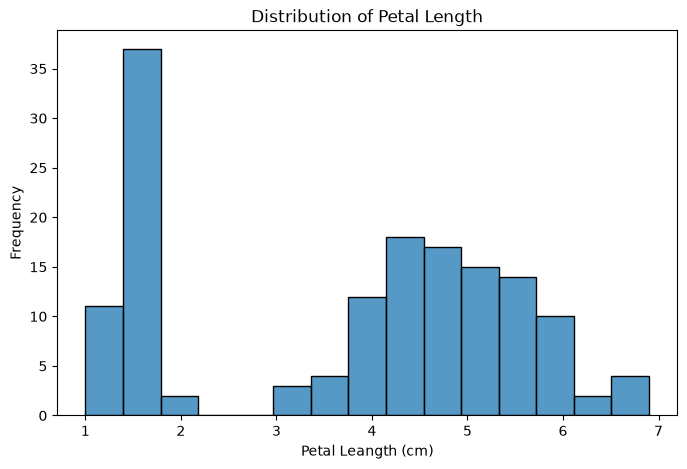

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="petal length (cm)", bins=15)

plt.title("Distribution of Petal Length")
plt.xlabel("Petal Leangth (cm)")
plt.ylabel("Frequency")
plt.show()

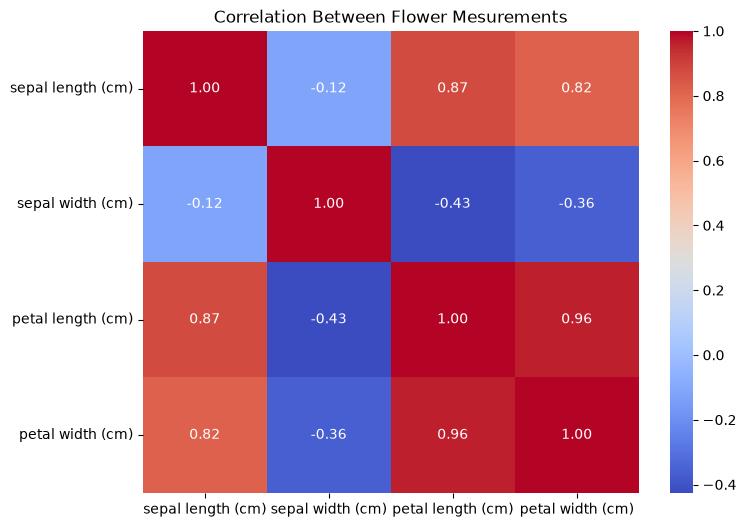

In [21]:
correlation =X.corr()
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Flower Mesurements")
plt.show()

In [22]:
print("Our features are:")
print(X.columns.tolist())
print("\nOur target is:")
print(y.name)

Our features are:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Our target is:
flower


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

Training data: (119, 4)
Testing data: (30, 4)


In [24]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
print("Our flower prediction model is trained!")

Our flower prediction model is trained!


In [25]:
predictions = model.predict(X_test)
print("Actual flower name:")
print(y_test.head(10).tolist())
print("\nPredicted flower names:")
print(predictions[:10].tolist())


Actual flower name:
['versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'virginica']

Predicted flower names:
['versicolor', 'versicolor', 'virginica', 'setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica', 'virginica']


In [26]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,predictions)
print("Model Accuracy:",accuracy * 100, "%")

Model Accuracy: 93.33333333333333 %


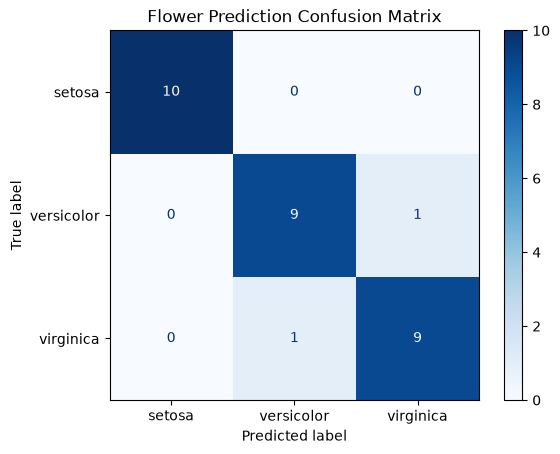

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm= confusion_matrix(y_test,predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)
display.plot(cmap="Blues")
plt.title("Flower Prediction Confusion Matrix")
plt.show()

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train,y_train)
rf_predictions =rf_model.predict(X_test)
print("random aforest model trained sucessfully!")

random aforest model trained sucessfully!


In [29]:
rf_accuracy = accuracy_score(y_test,rf_predictions)
print("Random Forest Accuracy:",rf_accuracy *100,"%")

Random Forest Accuracy: 93.33333333333333 %


In [30]:
dt_accuracy = accuracy_score(y_test,predictions)
rf_accuracy = accuracy_score(y_test,rf_predictions)
print("Desision Tree Accuracy:",dt_accuracy *100,"%")
print("Random Forest Accuracy:",rf_accuracy *100,"%")

Desision Tree Accuracy: 93.33333333333333 %
Random Forest Accuracy: 93.33333333333333 %


In [43]:
from sklearn.model_selection import cross_val_score

dt_scores = cross_val_score(
    model,
    X,
    y,
    cv=5
)
print("Decision Tree CV soures:",dt_scores)
print("Average accuracy:",dt_scores.mean() * 100,"%")

Decision Tree CV soures: [0.96666667 0.96666667 0.9        0.93333333 1.        ]
Average accuracy: 95.33333333333334 %


In [44]:
rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5
)
print("Random Forest CV scores:",rf_scores)
print("Average accuracy:",rf_scores.mean() * 100,"%")

Random Forest CV scores: [0.96666667 0.96666667 0.93333333 0.96666667 1.        ]
Average accuracy: 96.66666666666669 %


In [33]:
from sklearn.model_selection import GridSearchCV

parameters = {
    "n_estimators": [50,100,150,200],
    "max_depth": [None,3,5,20]
}
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    parameters,
    cv=5,
    scoring="accuracy"
)   
grid_search.fit(X_train,y_train)

print("Best parameters:",grid_search.best_params_)
print("Best accuracy:",grid_search.best_score_ * 100,"%")


Best parameters: {'max_depth': None, 'n_estimators': 50}
Best accuracy: 95.0 %


In [34]:
best_model = grid_search.best_estimator_
best_predictions = best_model.predict(X_test)
print("final tuned model is ready!")

final tuned model is ready!


In [35]:
from sklearn.metrics import accuracy_score

final_accuracy = accuracy_score(y_test,best_predictions)
print("Final Test Accuracy:",final_accuracy * 100,"%")

Final Test Accuracy: 90.0 %


In [40]:
import joblib

joblib.dump(best_model, "flower_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [37]:
import os 
print("Folder:",os.getcwd())
print("Model file exists:",os.path.exists("flower_model.pkl"))

Folder: C:\Users\God\data science
Model file exists: True


In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, best_predictions))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



petal width (cm)     0.450977
petal length (cm)    0.400579
sepal length (cm)    0.119886
sepal width (cm)     0.028558
dtype: float64


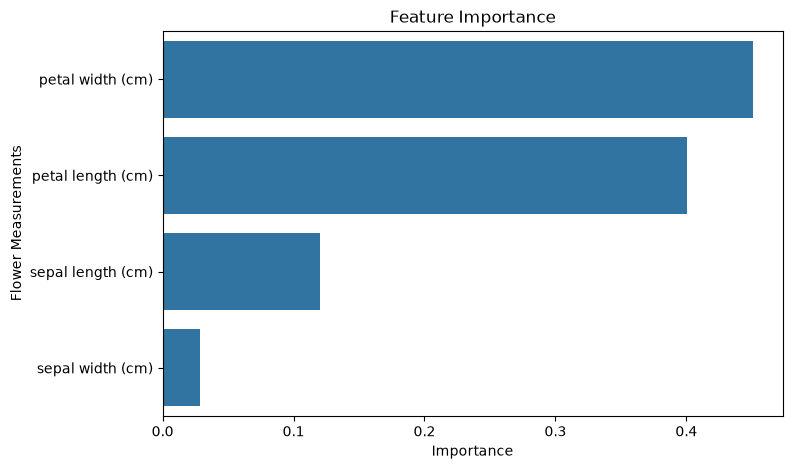

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Flower Measurements")
plt.show()

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

X_train_reduced = X_train.drop(columns=["sepal width (cm)"])
X_test_reduced = X_test.drop(columns=["sepal width (cm)"])
reduced_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=None,
    random_state=42
)

reduced_scores = cross_val_score(
    reduced_model,
    X_train_reduced,
    y_train,
    cv=5
)

print("Reduced model CV accuracy:",
      reduced_scores.mean() * 100, "%")


reduced_model.fit(X_train_reduced, y_train)

reduced_predictions = reduced_model.predict(X_test_reduced)

reduced_accuracy = accuracy_score(
    y_test,
    reduced_predictions
)

print("Reduced model test accuracy:",
      reduced_accuracy * 100, "%")

print("Original model test accuracy:",
      accuracy_score(y_test, best_predictions) * 100, "%")

Reduced model CV accuracy: 95.83333333333334 %
Reduced model test accuracy: 90.0 %
Original model test accuracy: 90.0 %


In [51]:

full_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5
)

reduced_scores = cross_val_score(
    reduced_model,
    X_train_reduced,
    y_train,
    cv=5
)

print("Original model CV:", full_scores.mean() * 100, "%")
print("Reduced model CV:", reduced_scores.mean() * 100, "%")

Original model CV: 95.0 %
Reduced model CV: 95.83333333333334 %


In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, reduced_predictions))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [50]:
import joblib

joblib.dump(reduced_model, "flower_model.pkl")
print("New three-feature model saved successfully!")

New three-feature model saved successfully!
